# Gold standard: wyniki

**Próba.** 100 wypowiedzi z populacji (43 991 wypowiedzi posłów, 13.11.2023–15.09.2026), po 50 na grupę, wylosowanych
warstwowo według etykiet modelu z pełnego przebiegu pipeline'u (Gemma 4 12B): w każdej grupie 20 wypowiedzi
tematycznych i sprzecznych według modelu, 15 tematycznych niesprzecznych i 15 nietematycznych. Wagi $w_h = N_h / n_h$.

**Anotacja.** Dwie etykiety na wypowiedź: tematyczna i (dla tematycznych) sprzeczna z AR6. Próbę podzieliło dwóch
anotatorów: FP oznaczył wypowiedzi 1–50, DK 51–100 (kolejność losowa, bez mówcy, klubu i warstwy).

**Źródło liczb.** `python src/estimate.py --anotacje data/gold/annotations_FP.csv data/gold/annotations_DK.csv`
(bootstrap warstwowy, 10 000 powtórzeń); notatnik tylko czyta pliki z `data/processed/results/`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(_root / "src"))

from amc import viz
from amc.viz import INK2, MUTED, AXIS, ACCENT, SECOND, save

viz.setup()
RES = _root / "data" / "processed" / "results"
MODEL = "gemma4_12b"
STRATUM = {1: "tematyczna i sprzeczna", 2: "tematyczna i niesprzeczna", 3: "nietematyczna"}

gold = pd.read_csv(RES / f"{MODEL}_gold.csv")
composition = pd.read_csv(RES / f"{MODEL}_composition.csv")
quality = pd.read_csv(RES / f"{MODEL}_quality.csv", index_col=0)
estimates = pd.read_csv(RES / f"{MODEL}_estimates.csv", index_col=0)
uncorrected = pd.read_csv(RES / f"{MODEL}_uncorrected.csv", index_col="grupa")
regression = pd.read_csv(RES / f"{MODEL}_regression.csv")


def ci(r, digits=2):
    return f"{r['wartosc']:.{digits}f} [{r['przedzial_2.5']:.{digits}f}; {r['przedzial_97.5']:.{digits}f}]"

## 1. Anotatorzy

In [2]:
gold.groupby("anotator").agg(wypowiedzi=("kolejnosc", "size"), od=("kolejnosc", "min"), do=("kolejnosc", "max"),
                             tematyczne=("tematyczna", "sum"), sprzeczne=("sprzeczna", "sum"))

,wypowiedzi,od,do,tematyczne,sprzeczne
anotator,,,,,
DK,50,51,100,19.0,7.0
FP,50,1,50,16.0,10.0


Części są rozłączne, więc zgodności anotatorów (kappa) nie da się policzyć. Obie części obejmują obie grupy i wszystkie
warstwy, bo kolejność w próbie jest losowa.

## 2. Skład próby: etykieta modelu a gold

In [3]:
c = composition.assign(warstwa=composition["warstwa"].map(STRATUM))
c["tematyczne_gold"] = c.pop("tematyczne").astype(str) + " / " + c["n_h"].astype(str)
c["sprzeczne_gold"] = c.pop("sprzeczne").astype(str) + " / " + c["n_h"].astype(str)
c.round({"waga": 1})

,grupa,warstwa,N_h,n_h,waga,tematyczne_gold,sprzeczne_gold
0,prawica,tematyczna i sprzeczna,60,20,3.0,15 / 20,12 / 20
1,prawica,tematyczna i niesprzeczna,828,15,55.2,4 / 15,2 / 15
2,prawica,nietematyczna,19274,15,1284.9,0 / 15,0 / 15
3,reszta,tematyczna i sprzeczna,28,20,1.4,11 / 20,2 / 20
4,reszta,tematyczna i niesprzeczna,729,15,48.6,5 / 15,1 / 15
5,reszta,nietematyczna,23072,15,1538.1,0 / 15,0 / 15


Model jako tematyczne i sprzeczne oznaczył 20 wypowiedzi w każdej grupie; według golda sprzecznych jest wśród nich 12
u prawicy i 2 u reszty. W warstwie nietematycznej (15 + 15 wypowiedzi) gold nie znalazł żadnej wypowiedzi o klimacie.
Ta warstwa ma największe wagi (ok. 1300–1500), więc jedna przeoczona wypowiedź tematyczna zmieniłaby mianownik o ponad
tysiąc wypowiedzi.

## 3. Jakość etykiet modelu (krok 5)

In [4]:
rows = []
for name, r in quality.iterrows():
    grupa, rest = name.split("_", 1)
    etap, miara = rest.rsplit("_", 1)
    rows.append({"etap": etap, "miara": miara, "grupa": grupa, "wynik": ci(r)})
q = pd.DataFrame(rows)
q = q[q["etap"].isin(["tematycznosc", "werdykt", "etykieta"])]
q.pivot_table(index=["etap", "miara"], columns="grupa", values="wynik", aggfunc="first", sort=False)

grupa                            prawica             reszta
etap         miara                                         
tematycznosc TPR       1.00 [1.00; 1.00]  1.00 [1.00; 1.00]
             TNR       0.97 [0.96; 0.98]  0.98 [0.97; 0.99]
             precyzja  0.30 [0.11; 0.53]  0.34 [0.14; 0.60]
             F1        0.46 [0.20; 0.70]  0.51 [0.25; 0.75]
werdykt      TPR       0.25 [0.11; 1.00]  0.05 [0.00; 1.00]
             TNR       0.92 [0.00; 1.00]  0.94 [0.78; 0.97]
             precyzja  0.80 [0.58; 1.00]  0.18 [0.00; 0.44]
             F1        0.38 [0.19; 0.94]  0.08 [0.02; 0.55]
etykieta     TPR       0.25 [0.11; 1.00]  0.05 [0.00; 1.00]
             TNR       1.00 [1.00; 1.00]  1.00 [1.00; 1.00]
             precyzja  0.60 [0.40; 0.80]  0.10 [0.00; 0.25]
             F1        0.35 [0.18; 0.82]  0.07 [0.02; 0.33]

Wartość z przedziałem 95% z bootstrapu; wagi warstw w każdej mierze.

- **Tematyczność.** Model oznacza jako tematyczne ok. trzy razy więcej wypowiedzi niż gold (precyzja 0,30 u prawicy,
  0,34 u reszty). TPR = 1 tylko dlatego, że w warstwie nietematycznej gold nie ma żadnej wypowiedzi o klimacie.
- **Etykieta końcowa** (tematyczna i sprzeczna). Precyzja 0,60 u prawicy i 0,10 u reszty, TPR 0,25 i 0,05. Błąd jest
  różnicowy między grupami, a niski TPR wynika z wypowiedzi sprzecznych według golda, które model uznał za niesprzeczne
  (warstwa 2, waga ok. 50).
- Przedziały są szerokie, a dla części miar bootstrap nie zawsze daje wartość (kolumna `bootstrap_brak` w pliku).

## 4. Odsetki z golda (krok 7)

In [5]:
w = composition.assign(T=composition["waga"] * composition["tematyczne"],
                       C=composition["waga"] * composition["sprzeczne"]).groupby("grupa")[["T", "C"]].sum()
table = pd.DataFrame({
    "tematyczne (gold, T̂)": w["T"].round(0),
    "sprzeczne (gold, Ĉ)": w["C"].round(0),
    "odsetek z golda": [ci(estimates.loc[f"p_{g}"], 3) for g in w.index],
    "tematyczne (model)": uncorrected["tematyczne"],
    "sprzeczne (model)": uncorrected["sprzeczne"].astype(int),
    "odsetek z modelu": uncorrected["odsetek"].round(3),
})
table

,"tematyczne (gold, T̂)","sprzeczne (gold, Ĉ)",odsetek z golda,tematyczne (model),sprzeczne (model),odsetek z modelu
grupa,,,,,,
prawica,266.0,146.0,0.551 [0.152; 0.972],888,60,0.068
reszta,258.0,51.0,0.199 [0.000; 0.626],757,28,0.037


In [6]:
d = estimates.loc["roznica"]
r = regression.iloc[0]
print(f"różnica prawica − reszta (gold): {ci(d, 3)}, dolna granica jednostronnego 95%: {d['dolna_95_jednostronna']:.3f}")
print(f"krok 6 (etykiety modelu): β1 = {r['beta1']:.3f}, SE = {r['se']:.3f}, p jednostronne = {r['p_jednostronne']:.3f}")
print("hipoteza:", "poparta" if d["dolna_95_jednostronna"] > 0 else "niepoparta")

różnica prawica − reszta (gold): 0.352 [-0.211; 0.924], dolna granica jednostronnego 95%: -0.112
krok 6 (etykiety modelu): β1 = 0.635, SE = 0.240, p jednostronne = 0.004
hipoteza: niepoparta


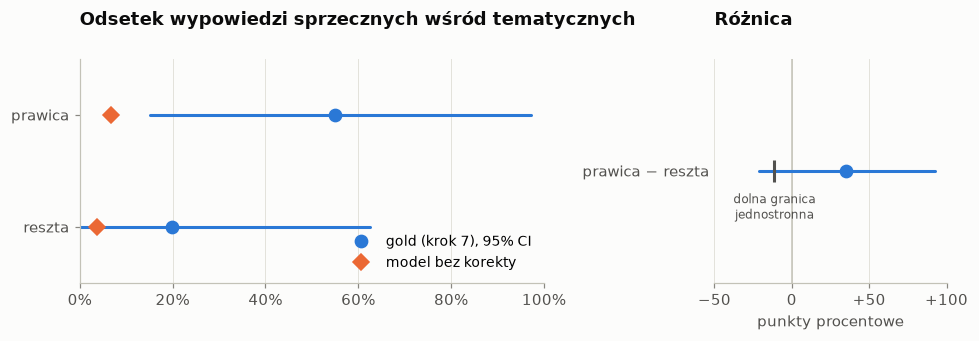

In [7]:
groups = ["prawica", "reszta"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [2, 1]})
for i, g in enumerate(groups):
    e = estimates.loc[f"p_{g}"]
    ax.plot([e["przedzial_2.5"], e["przedzial_97.5"]], [i, i], color=ACCENT, lw=2, solid_capstyle="round")
    ax.plot(e["wartosc"], i, "o", ms=8, color=ACCENT, label="gold (krok 7), 95% CI" if i == 0 else None)
    ax.plot(uncorrected.loc[g, "odsetek"], i, "D", ms=7, color=SECOND, label="model bez korekty" if i == 0 else None)
ax.set_yticks(range(len(groups)), groups)
ax.set_ylim(len(groups) - 0.5, -0.5)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:g}%"))
ax.grid(axis="y", visible=False)
ax.set_title("Odsetek wypowiedzi sprzecznych wśród tematycznych")
ax.legend(loc="lower right", fontsize=9)

ax2.axvline(0, color=AXIS, lw=1)
ax2.plot([d["przedzial_2.5"], d["przedzial_97.5"]], [0, 0], color=ACCENT, lw=2, solid_capstyle="round")
ax2.plot(d["wartosc"], 0, "o", ms=8, color=ACCENT)
ax2.plot(d["dolna_95_jednostronna"], 0, "|", ms=14, mew=2, color=INK2)
ax2.annotate("dolna granica\njednostronna", (d["dolna_95_jednostronna"], 0), xytext=(0, -14),
             textcoords="offset points", ha="center", va="top", fontsize=8, color=INK2)
ax2.set_yticks([0], ["prawica − reszta"])
ax2.set_ylim(0.5, -0.5)
ax2.set_xlim(-0.5, 1)
ax2.set_xticks([-0.5, 0, 0.5, 1], ["−50", "0", "+50", "+100"])
ax2.set_xlabel("punkty procentowe")
ax2.spines["left"].set_visible(False)
ax2.tick_params(axis="y", length=0)
ax2.grid(axis="y", visible=False)
ax2.set_title("Różnica")
fig.tight_layout()
save(fig, "gold_01_odsetki")

Gold daje dużo wyższe odsetki niż etykiety modelu w obu grupach: model zawyża mianownik (tematyczność), a gold dokłada
licznik z warstwy 2 (wypowiedzi sprzeczne, które model uznał za niesprzeczne). Różnica wychodzi dodatnia (+35 pp), ale
dolna granica jednostronnego przedziału 95% jest ujemna, więc według kroku 7 **hipoteza jest niepoparta**. Krok 6
(regresja na etykietach modelu) daje istotne β1 > 0, ale jest tylko pomocniczy.

## 5. Od czego zależy wynik

In [8]:
key = gold[(gold["warstwa"] == 2) & (gold["sprzeczna"] == 1)]
share = key.groupby("grupa")["waga"].sum() / w["C"]
display(key[["kolejnosc", "grupa", "waga", "anotator", "werdykt_modelu", "komentarz"]])
print("udział tych wypowiedzi w Ĉ:", share.round(2).to_dict())

,kolejnosc,grupa,waga,anotator,werdykt_modelu,komentarz
35,36,prawica,55.2,FP,0.0,NaN
58,59,prawica,55.2,DK,0.0,NaN
93,94,reszta,48.6,DK,0.0,NaN


udział tych wypowiedzi w Ĉ: {'prawica': 0.75, 'reszta': 0.95}


Licznik w obu grupach to głównie kilka wypowiedzi z warstwy 2 o wadze ok. 50: u prawicy dwie (ok. 3/4 $\hat{C}$),
u reszty jedna (prawie całe $\hat{C}$). Zmiana etykiety choćby jednej z nich mocno przesuwa odsetki, dlatego te
wypowiedzi warto opisać w analizie błędów.

**Ograniczenia.**
- 100 wypowiedzi: przedziały są szerokie, a warstwa nietematyczna (15 na grupę) słabo mierzy przeoczenia modelu.
- Bez części wspólnej anotatorów nie ma miary zgodności; etykiety golda traktujemy jako poprawne.